In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import os

ROOT_DIR = Path.cwd().parent
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from src import setup_workspace, query_to_df, ds3on1

# 1. Inicializar workspace y rutas
paths = setup_workspace()

# 2. Consultar directamente a PostgreSQL (vía DuckDB ATTACH)
#df = query_to_df("SELECT * FROM db.EuInfo;")

# 3. Análisis univariable 3-en-1
#ds3on1(df, 'happy', Desc=True, Stat=True, Graph=True)

✅ Workspace anclado en: /home/josu/Documentos/DataScienceCourse
📂 Ruta de tablas verificada: /home/josu/Documentos/DataScienceCourse/data/raw/Tables


🟢 < Module 7.1 > Exploratory Data Analysis (EDA), Stratified Distributions & Correlation Diagnostics

##### 🎯 Context & Objectives

In Exploratory Data Analysis (EDA), the goal is not merely to compute global summary statistics, but to uncover structural patterns, cluster behaviors, and dependencies between predictors and target variables across different economic contexts. In this exercise, you will perform an advanced EDA on your cleaned master survey dataset (`surveys_clean` combined with macro features). You will analyze ordinal vs. continuous variable distributions, evaluate non-linear relationships, and construct stratified correlation heatmaps comparing different European country clusters (e.g., high-income vs. medium/low-income economic groups).

##### 📑 Exercise Instructions

###### 1. Syntactic / Algorithmic Level (Pandas & Seaborn EDA Fundamentals)

Create a Python notebook (`notebooks/07_1_exploratory_data_analysis.ipynb`) that implements the following technical steps:

- **Statistical Profiling & Distribution Metrics** :
    
    - Compute robust central tendency and dispersion metrics (median, IQR, mean, standard deviation) for key survey ordinals (e.g., `happy`, `lrscale`, `stfdem`) and engineered features (`EmployType`, `emplno`).
        
    - Identify skewness and modal concentrations (such as the point mass at `0` in `emplno` for wage earners).
        
- **Stratified Correlation Analysis (Spearman vs. Pearson)** :
    
    - Explain why **Spearman’s rank correlation** is theoretically superior to Pearson's correlation when analyzing ordinal Likert scales (0–10) in survey data.
        
    - Generate a correlation matrix and visualize it using a Seaborn heatmap (`sns.heatmap`), ensuring proper diverging colormaps and annotation of correlation coefficients.
        

###### 2. Applied / Data Level (Socio-Economic Stratification & Insights)

Evaluate how macroeconomic country clusters modulate individual behaviors:

- **Multi-Group Comparison** :
    
    - Group your dataset by country economic tiers or regional clusters (`cntgrp_fc` / `std_region`).
        
    - Compare the distribution of political ideology (`lrscale`) or institutional trust (`trstlgl`) across different economic clusters using boxplots or violin plots (`sns.boxplot` / `sns.violinplot`).
        
- **Insight Synthesis** :
    
    - Document 3 key empirical findings from your visualizations that support your core research hypothesis (e.g., how educational level `edulvlb` or employment relation `EmployType` shifts political or social trust distributions).
        

##### 🌐 Official References & Documentation

- **Seaborn Statistical Plots** : [Seaborn Heatmap & Distribution Tutorial](https://seaborn.pydata.org/generated/seaborn.heatmap.html)
    
- **Pandas Statistical and Descriptive Functions** : [Pandas Descriptive Statistics Guide](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html)
    

##### 📚 Recommended Manuals & CheatSheets

- **DataCamp Seaborn Cheat Sheet** : [Python Seaborn Data Visualization Cheat Sheet](https://www.datacamp.com/cheat-sheet/python-seaborn-cheat-sheet)
    
- **Exploratory Data Analysis Best Practices** : [Python for Data Analysis — Exploratory Data Analysis Chapter](https://wesmckinney.com/book/)
    

💻 **Your Challenge:** Create the notebook `notebooks/07_1_exploratory_data_analysis.ipynb` in your local environment, run the stratified descriptive statistics and correlation heatmaps, and share your code or key findings here when ready for review! 🚀📊

In [2]:
#First of all lets load a sample dataframe for this excercise from the main Surveys table.
import duckdb as db
import os
from dotenv import load_dotenv
import pandas as pd
import numpy as np

load_dotenv()

pg_db = os.getenv("PGDATABASE")
pg_user = os.getenv("PGUSER")
pg_pass = os.getenv("PGPASSWORD")
pg_host = os.getenv("PGHOST")
pg_port = os.getenv("PGPORT")


con = db.connect()
    

con.execute("INSTALL postgres; LOAD postgres;")
    

attach_query = f"""
ATTACH IF NOT EXISTS 'dbname={pg_db} user={pg_user} password={pg_pass} host={pg_host} port={pg_port}' 
AS db (TYPE postgres);
"""
    

con.execute(attach_query)


df_raw = con.execute("""
    SELECT emplno, agea, emplrel, edulvlb, happy, lrscale, cntry, EmployType, trstprl, trstlgl
    FROM db.surveys
    WHERE COLUMNS(*) IS NOT NULL
""").df()

df_71 = pd.concat([
    g.sample(n=min(100, len(g)), random_state=42)
    for _, g in df_raw.groupby('cntry')
]).reset_index(drop=True)

print(f"Shape: {df_71.shape}")  # → (2400, 8)
del df_raw 

Shape: (2400, 10)


In [ ]:
Step 0, Problem framing:
-Research question:
 To what extent do regional location, national political-economic context, and country-specific factors explain variation in [variable social var] across European countries, 2004–2024?
-RQ1 (descriptive): How do [surveys_vars] vary across European regions and over time (2004–2024)?
-RQ2 (comparative): Is the variance in [variable social] between countries larger than the variance between regions within the same country?
-RQ3 (asociative): To what extent do national economic indicators (GDP per capita, unemployment, Gini) predict [surveys_vars] within and across countries?
-RQ4: Do European countries cluster more strongly by similarity in economic trend trajectories (2004–2024) than by national identity (political regime, cultural region, or historical bloc)?

🌟 ANÁLISIS 3-EN-1: [EMPLNO] 🌟

--------------------------------------------------
📖 1. DESCRIPCIÓN
--------------------------------------------------
  Familia estadística : NUMERIC
  Subtipo detectado   : DISCRETE_COUNT
  Detalle             : range 0-100, 24 values

--------------------------------------------------
🧮 2. ESTADÍSTICAS Y DIAGNÓSTICO
--------------------------------------------------

  [numeric/discrete_count]  (n=2400, nulls=0)
  Media: 0.2875 | Mediana: 0.0000
  Q1/Q3: 0.0000 / 0.0000 | IQR: 0.0000
  Min/Max: 0.0000 / 100.0000
  % ceros (masa puntual): 96.08%
  ⚠️  WARNING: >50% de los valores son 0. Considera transformación log1p() si usas modelos lineales.

--------------------------------------------------
📊 3. VISUALIZACIÓN ADAPTATIVA
--------------------------------------------------


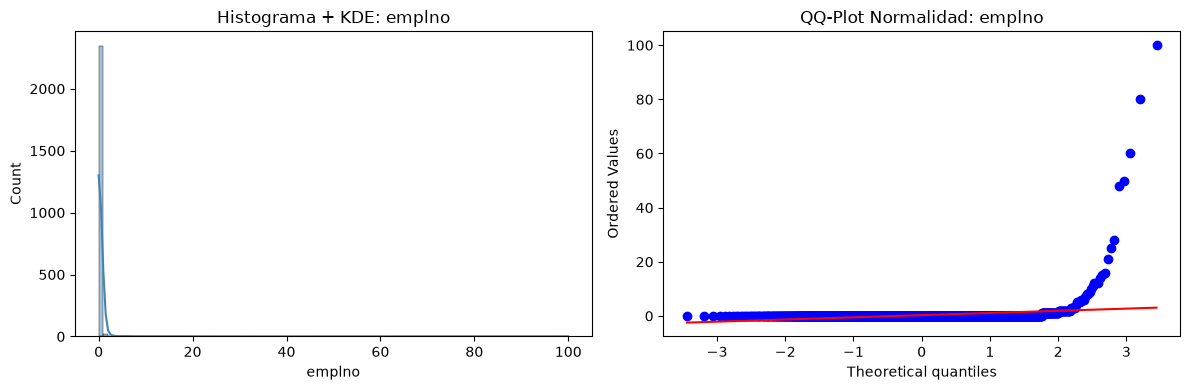

In [3]:
#First of all lets do a quick univariate analysis.
#1)Data Inspection:

ds3on1(df_71, 'emplno', Desc=True, Stat=True, Graph=True)

🌟 ANÁLISIS 3-EN-1: [AGEA] 🌟

--------------------------------------------------
📖 1. DESCRIPCIÓN
--------------------------------------------------
  Familia estadística : NUMERIC
  Subtipo detectado   : DISCRETE_COUNT
  Detalle             : range 15-999, 77 values

--------------------------------------------------
🧮 2. ESTADÍSTICAS Y DIAGNÓSTICO
--------------------------------------------------

  [numeric/discrete_count]  (n=2400, nulls=0)
  Media: 56.1200 | Mediana: 53.0000
  Q1/Q3: 37.0000 / 67.0000 | IQR: 30.0000
  Min/Max: 15.0000 / 999.0000
  % ceros (masa puntual): 0.00%

--------------------------------------------------
📊 3. VISUALIZACIÓN ADAPTATIVA
--------------------------------------------------


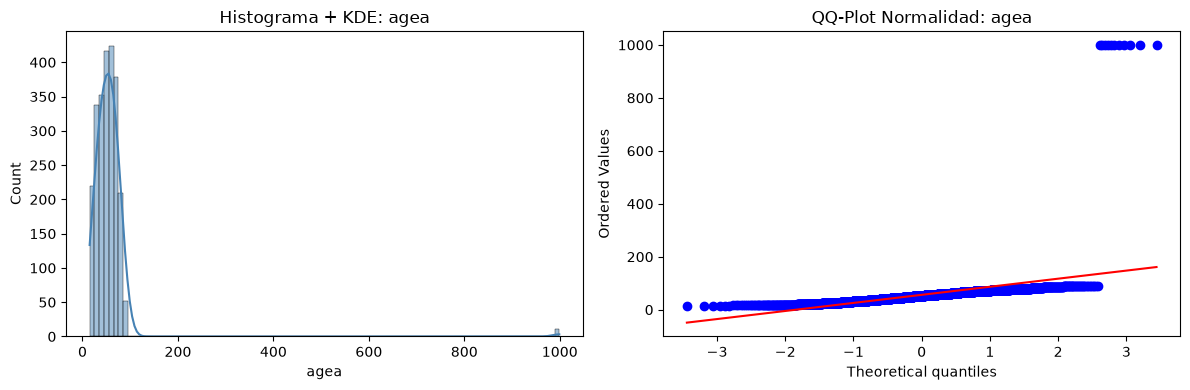

In [4]:
ds3on1(df_71, 'agea', Desc=True, Stat=True, Graph=True)

🌟 ANÁLISIS 3-EN-1: [EMPLREL] 🌟

--------------------------------------------------
📖 1. DESCRIPCIÓN
--------------------------------------------------
  Familia estadística : CATEGORICAL
  Subtipo detectado   : NOMINAL
  Detalle             : 2 categories

--------------------------------------------------
🧮 2. ESTADÍSTICAS Y DIAGNÓSTICO
--------------------------------------------------

  [categorical/nominal]  (n=2400, nulls=0)

  Top Valores:
    1                 2156  ( 89.8%)  ██████████████████████████████
    2                  244  ( 10.2%)  ███
  Únicos: 2
  ⚠️  WARNING: La categoría dominante supera el 50% de los datos.

--------------------------------------------------
📊 3. VISUALIZACIÓN ADAPTATIVA
--------------------------------------------------


/home/josu/Documentos/DataScienceCourse/src/descriptive_tools.py:203: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=vc.values, y=vc.index.astype(str), ax=axes[0], palette='Blues_r')


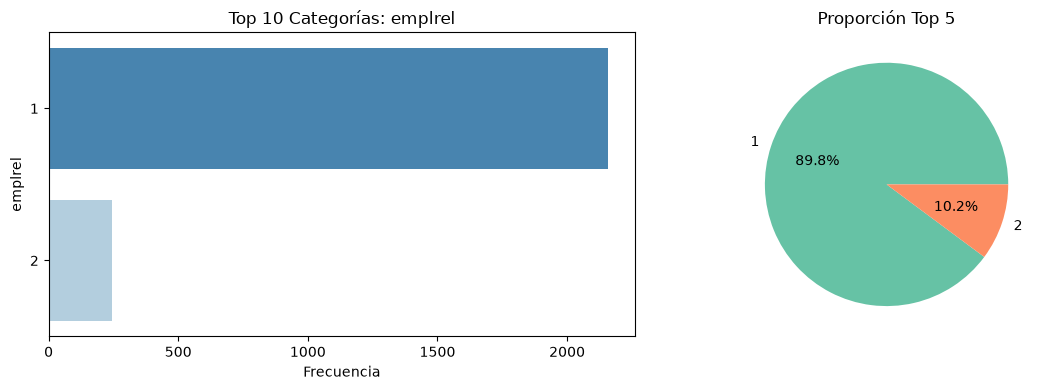

In [5]:
ds3on1(df_71, 'emplrel', Desc=True, Stat=True, Graph=True)

🌟 ANÁLISIS 3-EN-1: [EDULVLB] 🌟

--------------------------------------------------
📖 1. DESCRIPCIÓN
--------------------------------------------------
  Familia estadística : NUMERIC
  Subtipo detectado   : DISCRETE_COUNT
  Detalle             : range 0-9999, 29 values

--------------------------------------------------
🧮 2. ESTADÍSTICAS Y DIAGNÓSTICO
--------------------------------------------------

  [numeric/discrete_count]  (n=2400, nulls=0)
  Media: 463.3138 | Mediana: 322.0000
  Q1/Q3: 313.0000 / 610.0000 | IQR: 297.0000
  Min/Max: 0.0000 / 9999.0000
  % ceros (masa puntual): 1.04%

--------------------------------------------------
📊 3. VISUALIZACIÓN ADAPTATIVA
--------------------------------------------------


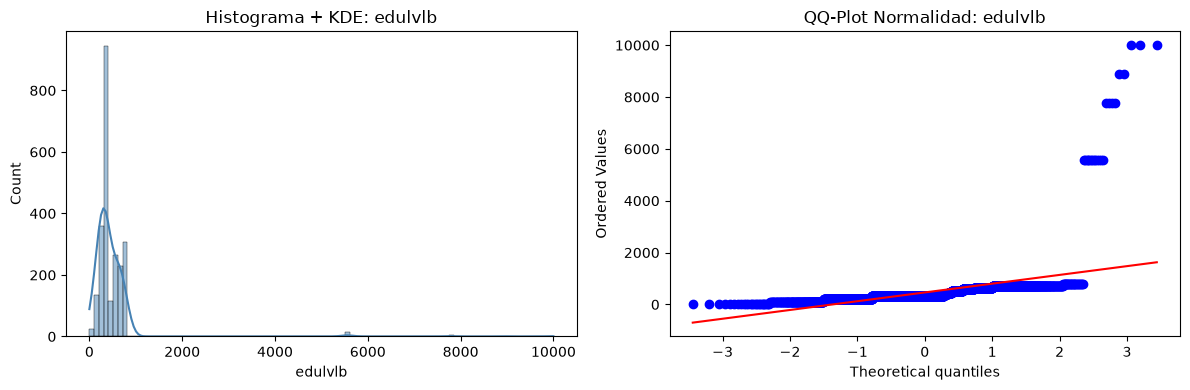

In [6]:
ds3on1(df_71, 'edulvlb', Desc=True, Stat=True, Graph=True)

In [ ]:
-edulvlb: – Education and profesional level of the respondent, ISCED codification . Discrete, non-negative ordinal value (the more qualification, higher code respondent has.).
          - Outliers / sentinel values: 6666, 7777, 8888, 9999 are non-response or data-entry error codes. Also there is a respondent minority class on 0 value, 
"ISCED 0 (early childhood / no formal education): ~1% of respondents"
          - Median observation tell us our frecuency or porportion is located with mayor mass in the Q2-Q3 range. We can observe an non high leptokurtosis and right-skewed distribution.          
          - The 50% of our mass fluctuates from 313(Q1)ISCED code to 610(Q3) code. This mas is located in 297(IQR) codification range.
          - This variable could be transformed in 3 or 4 categorical groups, also be binned in 3 variables in the case we need for the feature engineering.
                                                                                                                               

🌟 ANÁLISIS 3-EN-1: [HAPPY] 🌟

--------------------------------------------------
📖 1. DESCRIPCIÓN
--------------------------------------------------
  Familia estadística : NUMERIC
  Subtipo detectado   : DISCRETE_COUNT
  Detalle             : range 0-99, 14 values

--------------------------------------------------
🧮 2. ESTADÍSTICAS Y DIAGNÓSTICO
--------------------------------------------------

  [numeric/discrete_count]  (n=2400, nulls=0)
  Media: 7.8204 | Mediana: 8.0000
  Q1/Q3: 7.0000 / 9.0000 | IQR: 2.0000
  Min/Max: 0.0000 / 99.0000
  % ceros (masa puntual): 0.46%

--------------------------------------------------
📊 3. VISUALIZACIÓN ADAPTATIVA
--------------------------------------------------


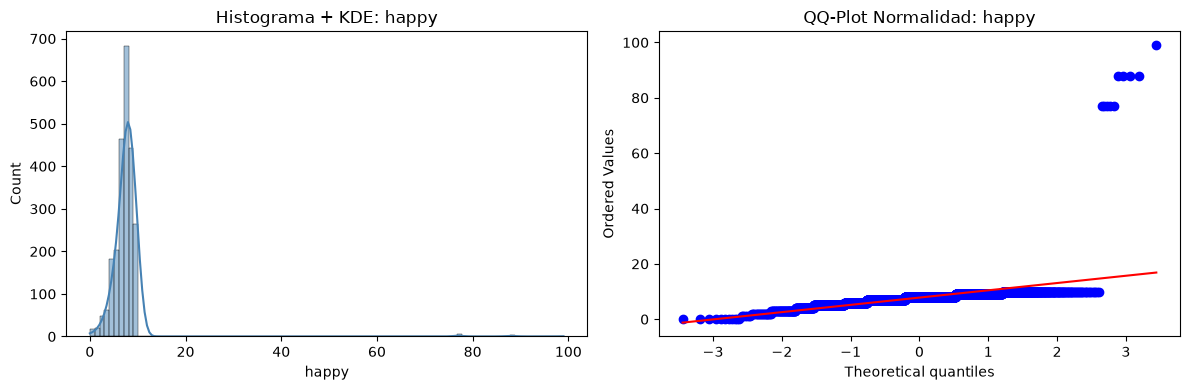

In [7]:
ds3on1(df_71, 'happy', Desc=True, Stat=True, Graph=True)

In [ ]:
-happy: – State of happyness the respondent has, being 0 unhappy and 10 the max value on lickert scale. Discrete, non-negative ordinal value.
        - Outliers / sentinel values: 66, 77, 88, 99 are non-response or data-entry error codes.
        - The mean (7.8) is slightly below the median (8), consistent with the left skew: the thin tail of low-satisfaction responses (0–5) pulls the mean downward, while the median remains anchored in the central mass at 7–8.
        - The iqr range is so compressed, and the mean-median relation tells us in that 50% of mass respondents, respondents are more close to 8 value of happy than 7.
        - Implication: The limited dynamic range in the central mass makes the raw variable poorly discriminative for modelling.
        Options:
            -Binarize: satisfied = happy ≥ 8 (aligns with Eurostat's own "satisfied / not satisfied" split). Best if the RQ is "what predicts being satisfied?"
            -Categorical (3–4 groups): Unhappy (0–4), Neutral (5–6), Satisfied (7–8), Very satisfied (9–10). Best for ordinal regression (proportional odds).
            -Keep as interval (0–10): Defensible for OLS / random effects if you assume equal spacing. Best if the RQ is "what predicts the level of satisfaction?" and you want to use the full range.
        The choice depends on which RQ it serves. For RQ3 (economic predictors), the interval version preserves more information; for RQ4 (clustering), the categorical version is more robust.

count                                                             2400
categories count                                                    24
Uniques frecuency    cntry
AT    100
BE    100
BG    100
CH    100
...
min                                                                 AT
max                                                                 SK
dtype: object


/tmp/ipykernel_7263/243739368.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=counts, x='count', y='cntry', palette='viridis', legend=False)


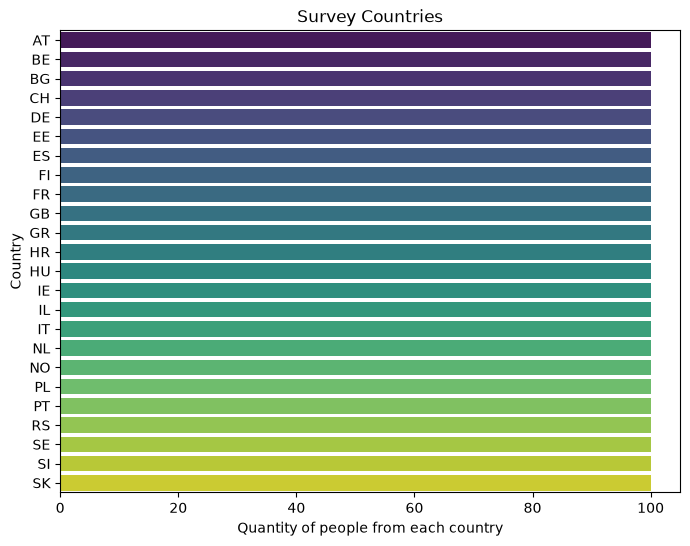

In [24]:

col=df_71['cntry']
def quick_stats(col):
    mode = col.mode()
    return pd.Series({
        'count':  col.count(),
        'categories count': col.nunique(),
        'Uniques frecuency': col.value_counts(),
        #'mean':   col.mean(),
        #'std':    col.std(),
        'min':    col.min(),
        #'Q1':     col.quantile(.25),
        #'median': col.median(),
        #'Q3':     col.quantile(.75),
        'max':    col.max(),
        #'mode':   mode[0] if not mode.empty else np.nan,
        #'skew':   col.skew(),
        #'kurtosis': col.kurt()
    }) 
print(quick_stats(col))
#Being non factorized discrete categorical column, most of our metrics can't be used.
import matplotlib.pyplot as plt
import seaborn as sns
# 1. Sort and calculate frecuencies
counts = df_71['cntry'].value_counts().reset_index()
counts.columns = ['cntry', 'count']

plt.figure(figsize=(8, 6))
# 2. Swap the axis being Y axis the country codes and X the number of rows.
sns.barplot(data=counts, x='count', y='cntry', palette='viridis', legend=False)

plt.title('Survey Countries')
plt.xlabel('Quantity of people from each country')
plt.ylabel('Country')
plt.show()

In [ ]:
-cntry: – the string values (countries) are ordered in order of appearance, 
it is the variable that we have used to create the dataframe using grouping and maximum number of random samples.

🌟 ANÁLISIS 3-EN-1: [LRSCALE] 🌟

--------------------------------------------------
📖 1. DESCRIPCIÓN
--------------------------------------------------
  Familia estadística : NUMERIC
  Subtipo detectado   : DISCRETE_COUNT
  Detalle             : range 0-99, 14 values

--------------------------------------------------
🧮 2. ESTADÍSTICAS Y DIAGNÓSTICO
--------------------------------------------------

  [numeric/discrete_count]  (n=2400, nulls=0)
  Media: 14.2346 | Mediana: 5.0000
  Q1/Q3: 4.0000 / 7.0000 | IQR: 3.0000
  Min/Max: 0.0000 / 99.0000
  % ceros (masa puntual): 3.21%

--------------------------------------------------
📊 3. VISUALIZACIÓN ADAPTATIVA
--------------------------------------------------


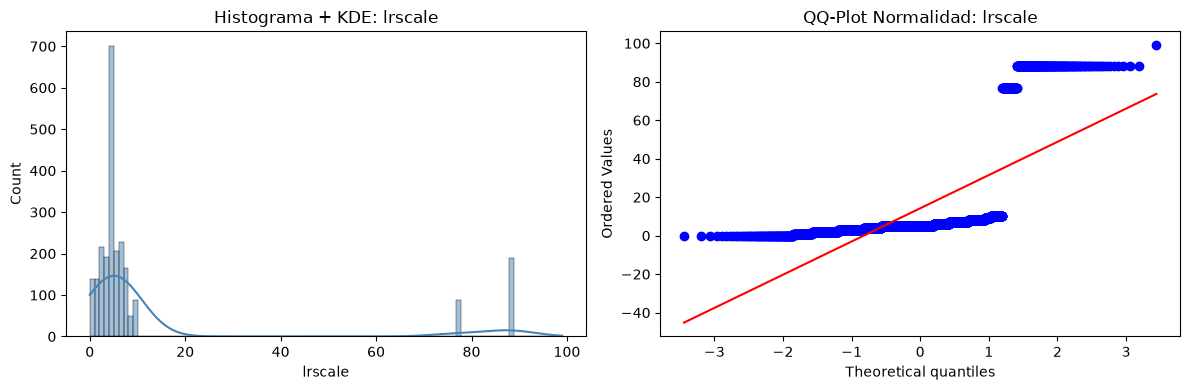

In [27]:
ds3on1(df_71, 'lrscale', Desc=True, Stat=True, Graph=True)

🌟 ANÁLISIS 3-EN-1: [EMPLOYTYPE] 🌟

--------------------------------------------------
📖 1. DESCRIPCIÓN
--------------------------------------------------
  Familia estadística : CATEGORICAL
  Subtipo detectado   : NOMINAL
  Detalle             : 2 categories

--------------------------------------------------
🧮 2. ESTADÍSTICAS Y DIAGNÓSTICO
--------------------------------------------------

  [categorical/nominal]  (n=2400, nulls=0)

  Top Valores:
    1                 2156  ( 89.8%)  ██████████████████████████████
    2                  244  ( 10.2%)  ███
  Únicos: 2
  ⚠️  WARNING: La categoría dominante supera el 50% de los datos.

--------------------------------------------------
📊 3. VISUALIZACIÓN ADAPTATIVA
--------------------------------------------------


/home/josu/Documentos/DataScienceCourse/src/descriptive_tools.py:203: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=vc.values, y=vc.index.astype(str), ax=axes[0], palette='Blues_r')


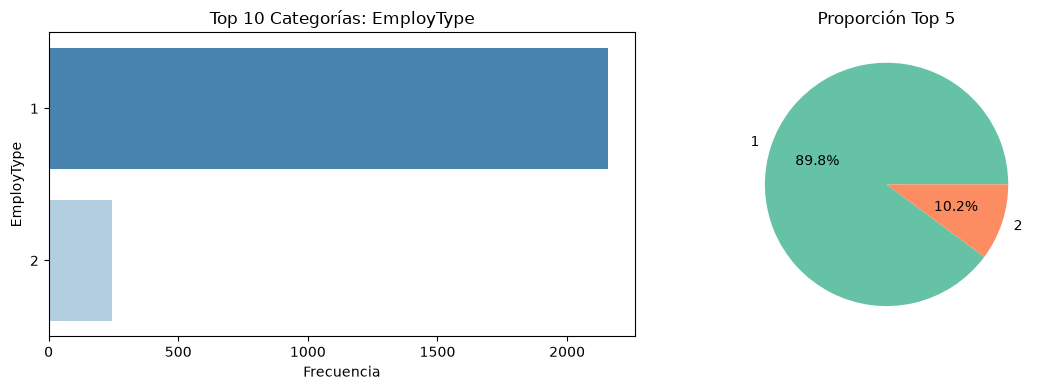

In [25]:
ds3on1(df_71, 'EmployType', Desc=True, Stat=True, Graph=True)